#**Nearest-Neighbor Search Engine (KD-Tree)**

# **PART 1: Dataset & KD Tree Construction**

###**Installing ucimlrepo and Dataset**

In [ ]:
!pip install ucimlrepo


**Purpose:** Installs `ucimlrepo`, which allows us to download datasets directly from the UCI Machine Learning Repository.


**Purpose:** Fetches the Forest Covertype dataset using its UCI dataset ID (31) and displays its metadata, features and variable descriptions.

###**Import libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully.")

Libraries imported successfully.



**Purpose:** Imports the required libraries for numerical operations, data handling, visualization, train-test splitting and feature standardization.


###**Acquire the dataset**

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Fetch the Forest Covertype dataset
covertype = fetch_ucirepo(id=31)

# Separate features and target
X = covertype.data.features.copy()
y = covertype.data.targets.copy()

# Convert target into a one-dimensional Series
if isinstance(y, pd.DataFrame):
    y = y.iloc[:, 0]

# Display dataset information
print("Dataset downloaded successfully!")
print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst five records:")
display(X.head())

print("\nFirst five target labels:")
display(y.head())


Dataset downloaded successfully!

Feature shape: (581012, 54)
Target shape: (581012,)

First five records:


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,0
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,0
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,0
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,0
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,0



First five target labels:


,Cover_Type
0,5
1,5
2,2
3,2
4,5


**Purpose:** Downloads the Forest Covertype dataset and separates it into input features (`X`) and target labels (`y`). Displays the dataset shape and first five records for initial inspection.

###**Inspect and clean the data**

In [ ]:
import numpy as np
import pandas as pd

# Display column names and data types
print("Column names:")
print(X.columns.tolist())

print("\nData types:")
print(X.dtypes)

print("\nMissing values in features:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

print("\nDuplicate feature rows:", X.duplicated().sum())

# Combine features and target
data = X.copy()
data["Cover_Type"] = np.asarray(y).ravel()

# Remove rows with missing values
data = data.dropna().reset_index(drop=True)

# Remove rows containing infinite values
numeric_columns = data.select_dtypes(include=np.number).columns

data = data[
    np.isfinite(data[numeric_columns]).all(axis=1)
].reset_index(drop=True)

# Count duplicate rows before removing them
print("\nDuplicate rows before removal:", data.duplicated().sum())

# Remove exact duplicate rows, including the target
data = data.drop_duplicates().reset_index(drop=True)

# Separate cleaned features and target
X = data.drop(columns=["Cover_Type"]).copy()
y = data["Cover_Type"].copy()

# Ensure all features are numerical
X = X.apply(pd.to_numeric, errors="raise")

# Display cleaning results
print("\nCleaned dataset shape:", data.shape)
print("Cleaned feature shape:", X.shape)
print("Cleaned target shape:", y.shape)

print("\nRemaining missing values:", data.isnull().sum().sum())
print("Remaining infinite values:", np.isinf(X.to_numpy()).sum())
print("Remaining duplicate rows:", data.duplicated().sum())


Column names:
['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1', 'Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5', 'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10', 'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14', 'Soil_Type15', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18', 'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22', 'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26', 'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30', 'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34', 'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38', 'Soil_Type39', 'Soil_Type40', 'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4']

Data types:
Elevation                             int64
Aspect                        


**Purpose:** Checks data types, missing values, duplicates and infinite values. Removes rows containing missing or non-finite values and ensures all features are numeric.


###**Feature Selection**

In [ ]:
import numpy as np
import pandas as pd

from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler

# Combine feature statistics for all available features
feature_analysis = pd.DataFrame({
    "Unique_Values": X.nunique(),
    "Variance": X.var(),
    "Data_Type": X.dtypes.astype(str)
})

# Identify binary and higher-cardinality features
feature_analysis["Feature_Type"] = np.where(
    feature_analysis["Unique_Values"] <= 2,
    "Binary",
    "Non-binary"
)

print("Feature analysis:")
display(
    feature_analysis.sort_values(
        "Unique_Values",
        ascending=False
    )
)

print(
    "\nBinary feature count:",
    (feature_analysis["Feature_Type"] == "Binary").sum()
)

print(
    "Non-binary feature count:",
    (feature_analysis["Feature_Type"] == "Non-binary").sum()
)

# Select the 10 terrain features for the KD-Tree experiment
selected_features = [
    "Elevation",
    "Aspect",
    "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am",
    "Hillshade_Noon",
    "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points",
]

# Verify that all selected features exist
missing_features = [
    col for col in selected_features
    if col not in X.columns
]

if missing_features:
    raise ValueError(
        f"Selected features are missing: {missing_features}. "
        "Check that the correct Covertype dataset was loaded."
    )

# Select the 10 features
X_selected = X[selected_features].copy()

print("\nSelected features:")
print(selected_features)

print("\nSelected feature statistics:")
display(X_selected.describe().T)

print("\nUnique values in selected features:")
print(X_selected.nunique())


Feature analysis:


,Unique_Values,Variance,Data_Type,Feature_Type
Horizontal_Distance_To_Fire_Points,5827,1.753493e+06,int64,Non-binary
Horizontal_Distance_To_Roadways,5785,2.431276e+06,int64,Non-binary
Elevation,1978,7.839145e+04,int64,Non-binary
Vertical_Distance_To_Hydrology,700,3.398334e+03,int64,Non-binary
Horizontal_Distance_To_Hydrology,551,4.517723e+04,int64,Non-binary
Aspect,361,1.252468e+04,int64,Non-binary
Hillshade_3pm,255,1.464940e+03,int64,Non-binary
Hillshade_9am,207,7.166269e+02,int64,Non-binary
Hillshade_Noon,185,3.908014e+02,int64,Non-binary
Slope,67,5.607377e+01,int64,Non-binary



Binary feature count: 44
Non-binary feature count: 10

Selected features:
['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points']

Selected feature statistics:


,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.365301,279.984734,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.656807,111.913721,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.103704,7.488242,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.428217,212.549356,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.418855,58.295232,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.146611,1559.254870,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.146049,26.769889,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.318716,19.768697,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.528263,38.274529,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.291226,1324.195210,0.0,1024.0,1710.0,2550.0,7173.0



Unique values in selected features:
Elevation                             1978
Aspect                                 361
Slope                                   67
Horizontal_Distance_To_Hydrology       551
Vertical_Distance_To_Hydrology         700
Horizontal_Distance_To_Roadways       5785
Hillshade_9am                          207
Hillshade_Noon                         185
Hillshade_3pm                          255
Horizontal_Distance_To_Fire_Points    5827
dtype: int64


**Purpose:** To select top 10 features as KNN suffers from the curse of dimensionality.

###**Explore the class distribution**

Number of records in each class:
Cover_Type
1    211840
2    283301
3     35754
4      2747
5      9493
6     17367
7     20510
Name: count, dtype: int64


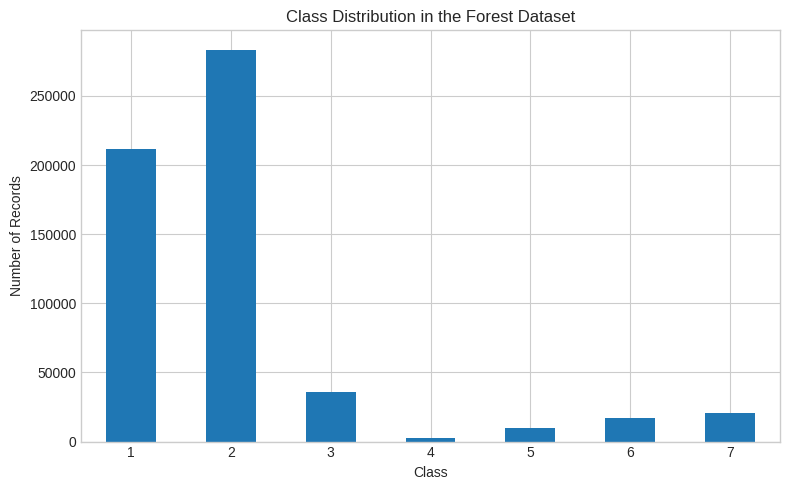

In [ ]:
# Count records in each class
class_counts = y.value_counts().sort_index()

print("Number of records in each class:")
print(class_counts)

# Plot class distribution
plt.figure(figsize=(8, 5))
class_counts.plot(kind="bar")

plt.title("Class Distribution in the Forest Dataset")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Purpose:** Counts the number of records in each target class and visualizes their distribution using a bar chart. Helps identify class imbalance in the dataset.


###**Separate features and target, then split the data**

In [ ]:
# Separate input features and target labels
X = X.astype(float)
y = y.astype(int)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Reset indices for easier integration with the KD-Tree
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("Training label shape:", y_train.shape)
print("Testing label shape:", y_test.shape)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

Training feature shape: (464809, 54)
Testing feature shape: (116203, 54)
Training label shape: (464809,)
Testing label shape: (116203,)

Training records: 464809
Testing records: 116203



**Purpose:** Separates features and labels, then splits the dataset into 80% training and 20% testing sets. Stratification maintains class proportions in both sets. Indices are reset for easier handling.


###**Standardize the features**

In [ ]:
scaler = StandardScaler()

# Fit only on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same training-set statistics
X_test_scaled = scaler.transform(X_test)

print("\nTraining data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nTraining feature means (approximately 0):")
print(np.round(X_train_scaled.mean(axis=0), 4))

print("\nTraining feature standard deviations (approximately 1):")
print(np.round(X_train_scaled.std(axis=0), 4))


Training data shape: (464809, 54)
Testing data shape: (116203, 54)

Training feature means (approximately 0):
[-0.  0. -0.  0.  0. -0. -0. -0.  0.  0.  0.  0. -0.  0.  0.  0. -0.  0.
 -0.  0. -0.  0. -0.  0.  0.  0. -0. -0. -0. -0. -0.  0.  0. -0.  0.  0.
  0. -0. -0. -0.  0.  0. -0. -0.  0.  0. -0.  0.  0. -0.  0. -0. -0. -0.]

Training feature standard deviations (approximately 1):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]



**Purpose:** Standardizes the features using `StandardScaler` so that each feature has approximately zero mean and unit variance. The scaler is fitted on training data and applied to test data using the same statistics to prevent data leakage.


##**KD-Tree construction from scratch**

In [ ]:
import numpy as np
import heapq

class KDTreeNode:
    def __init__(self, point, label, index, axis):
        self.point = point
        self.label = label
        self.index = index
        self.axis = axis
        self.left = None
        self.right = None


class KDTree:
    def __init__(self, X, y):
        self.X = np.asarray(X, dtype=float)
        self.y = np.asarray(y)

        if self.X.ndim != 2:
            raise ValueError("X must be a 2D array.")

        if len(self.X) != len(self.y):
            raise ValueError("X and y must have equal lengths.")

        if len(self.X) == 0:
            raise ValueError("Training data cannot be empty.")

        if not np.isfinite(self.X).all():
            raise ValueError("X must contain only finite values.")

        self.n_samples, self.n_features = self.X.shape

        self.root = self.build_tree()

    def build_tree(self):
        indices = np.arange(self.n_samples)
        return self._build(indices, depth=0)

    def _build(self, indices, depth):
        if len(indices) == 0:
            return None

        axis = depth % self.n_features

        median_position = len(indices) // 2

        order = np.argpartition(
            self.X[indices, axis],
            median_position
        )

        sorted_indices = indices[order]
        median_index = sorted_indices[median_position]

        node = KDTreeNode(
            point=self.X[median_index].copy(),
            label=self.y[median_index],
            index=int(median_index),
            axis=axis
        )

        node.left = self._build(
            sorted_indices[:median_position],
            depth + 1
        )

        node.right = self._build(
            sorted_indices[median_position + 1:],
            depth + 1
        )

        return node

    def query(self, query_point, k=5):
        query_point = np.asarray(query_point, dtype=float)

        if query_point.shape != (self.n_features,):
            raise ValueError(
                f"Query must contain {self.n_features} features."
            )

        if not np.isfinite(query_point).all():
            raise ValueError("Query must contain only finite values.")

        if not isinstance(k, (int, np.integer)) or isinstance(k, bool):
            raise ValueError("k must be a positive integer.")

        if k < 1:
            raise ValueError("k must be at least 1.")

        k = min(k, self.n_samples)

        # Store the K nearest candidates in a max-heap.
        # Each item contains negative squared distance and index.

        nearest = []

        def search(node):
            if node is None:
                return

            difference = query_point - node.point
            distance_squared = float(np.dot(difference, difference))

            candidate = (
                -distance_squared,
                -node.index,
                node.index,
                node.label
            )

            if len(nearest) < k:
                heapq.heappush(nearest, candidate)

            elif (
                distance_squared < -nearest[0][0]
                or (
                    distance_squared == -nearest[0][0]
                    and node.index < nearest[0][2]
                )
            ):
                heapq.heapreplace(nearest, candidate)

            axis = node.axis
            axis_difference = query_point[axis] - node.point[axis]

            if axis_difference <= 0:
                near_branch = node.left
                far_branch = node.right
            else:
                near_branch = node.right
                far_branch = node.left

            search(near_branch)

            # Explore the other branch if it may contain a closer point.
            if (
                len(nearest) < k
                or axis_difference ** 2 <= -nearest[0][0]
            ):
                search(far_branch)

        search(self.root)

        results = [
            (np.sqrt(-item[0]), item[3], item[2])
            for item in nearest
        ]

        results.sort(key=lambda item: (item[0], item[2]))

        return results

    def get_tree_size(self):
        def count(node):
            if node is None:
                return 0

            return 1 + count(node.left) + count(node.right)

        return count(self.root)

    def get_tree_depth(self):
        def depth(node):
            if node is None:
                return 0

            return 1 + max(
                depth(node.left),
                depth(node.right)
            )

        return depth(self.root)


**Purpose:** Implements the KD-Tree from scratch.

- `KDTreeNode` stores a point, its label, original index, splitting axis and child pointers.
- `KDTree` recursively builds a tree using median-based splitting and cycles through feature dimensions.
- `query()` uses a max-heap to maintain the K nearest neighbours and branch pruning to avoid unnecessary searches.
- `get_tree_size()` and `get_tree_depth()` provide tree statistics.

**Data structure:** Binary Tree + Max-Heap.


###**KD Tree Using Sample Data**

In [ ]:
# Example dataset with two features
X = np.array([
    [2, 3],
    [5, 4],
    [9, 6],
    [4, 7],
    [8, 1],
    [7, 2]
])

# Example class labels
y = np.array([0, 0, 1, 0, 1, 1])

# Create the KD-Tree
kd_tree = KDTree(X, y)

print("KD-Tree created successfully!")
print("Number of nodes:", kd_tree.get_tree_size())
print("Tree depth:", kd_tree.get_tree_depth())

KD-Tree created successfully!
Number of nodes: 6
Tree depth: 3



**Purpose:** Tests KD-Tree construction using a small two-dimensional example dataset. Displays the total number of nodes and tree depth to verify the construction.


###**KD Tree Using Forest Dataset**

In [ ]:
kd_tree = KDTree(
    X_train_scaled,
    y_train
)

print("Forest KD-Tree created successfully!")
print("Training records:", kd_tree.n_samples)
print("Number of features:", kd_tree.n_features)
print("Number of nodes:", kd_tree.get_tree_size())
print("Tree depth:", kd_tree.get_tree_depth())

Forest KD-Tree created successfully!
Training records: 464809
Number of features: 54
Number of nodes: 464809
Tree depth: 19


**Purpose:** Constructs the KD-Tree using the actual standardized Forest Covertype training dataset. Displays the number of training records, features, nodes and tree depth.

# **PART 2: KD Tree KNN**

In [ ]:
import numpy as np
from collections import Counter

class KDTreeKNN:
    def __init__(self, k=5):
        self.k = k
        self.tree = None
        self.y = None

    def fit(self, X, y):
        self.y = np.asarray(y)
        self.tree = KDTree(X, y)
        return self

    def predict_one(self, q):
        results = self.tree.query(q, k=self.k)
        votes = Counter(label for _, label, _ in results)
        top = max(votes.values())
        tied = {lbl for lbl, c in votes.items() if c == top}
        for _, label, _ in results:
            if label in tied:
                return label

    def predict(self, Q):
        return np.array([self.predict_one(q) for q in Q])

    def score(self, Q, y_true):
        return float(np.mean(self.predict(Q) == np.asarray(y_true)))


**Purpose:** Implements KNN classification using the previously constructed KD-Tree.

- `fit()` builds the KD-Tree using training data.
- `predict_one()` retrieves K nearest neighbours and performs majority voting.
- Ties are resolved using the nearest neighbour's label.
- `predict()` classifies multiple queries.
- `score()` calculates classification accuracy.

**Data structure:** KD-Tree + Counter for majority voting.


In [ ]:
kd = KDTreeKNN(k=5).fit(X_train_scaled, y_train)
print("accuracy:", kd.score(X_test_scaled, y_test))


**Purpose:** Trains the KD-Tree KNN classifier with K = 5 using standardized training data and evaluates its classification accuracy on the test dataset.


# **PART 3: Brute Force KNN algo**

In [ ]:
import time
import heapq
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter


class BaseKNN:

    def __init__(self, k=5):
        self.k = k
        self.X = None
        self.y = None

    def fit(self, X, y=None):
        raise NotImplementedError

    def query(self, q, k=None):
        raise NotImplementedError

    def predict_one(self, q):
        _, idxs = self.query(q)
        votes = Counter(self.y[i] for i in idxs)
        top = max(votes.values())
        tied = {lbl for lbl, c in votes.items() if c == top}
        for i in idxs:                      # vote tie -> nearest neighbor's label
            if self.y[i] in tied:
                return self.y[i]

    def predict(self, Q):
        return np.array([self.predict_one(q) for q in Q])

    def score(self, Q, y_true):
        return float(np.mean(self.predict(Q) == np.asarray(y_true)))


**Purpose:** Defines a reusable base class for KNN classifiers.

- `fit()` and `query()` define methods to be implemented by child classes.
- `predict_one()` performs majority voting among K neighbours.
- `predict()` classifies multiple query points.
- `score()` calculates classification accuracy.

Tie-breaking is handled using the nearest neighbour's label.


In [ ]:
class BruteForceKNN(BaseKNN):
    def fit(self, X, y=None):
        self.X = np.asarray(X, dtype=float)
        self.y = None if y is None else np.asarray(y)
        return self

    @staticmethod
    def _dist_sq(a, b):
        s = 0.0
        for i in range(len(a)):
            d = a[i] - b[i]
            s += d * d
        return s

    def query(self, q, k=None):
        k = min(k or self.k, len(self.X))
        if len(q) != self.X.shape[1]:
            raise ValueError("query dimension does not match data")

        heap = []  # max-heap of the k best: (-dist_sq, -index)
        for i in range(len(self.X)):
            d = self._dist_sq(self.X[i], q)
            if len(heap) < k:
                heapq.heappush(heap, (-d, -i))
            elif d < -heap[0][0]:
                heapq.heapreplace(heap, (-d, -i))

        result = sorted((-nd, -ni) for nd, ni in heap)
        return [d ** 0.5 for d, _ in result], [i for _, i in result]


**Purpose:** Implements brute-force nearest-neighbour search by calculating the Euclidean distance between the query point and every training point.

- `_dist_sq()` calculates squared Euclidean distance.
- `query()` maintains the K closest candidates using a max-heap.
- The final neighbours are sorted by distance.

**Data structure:** Max-Heap.

Unlike KD-Tree, this approach checks every training sample without branch pruning.


In [ ]:
rng = np.random.default_rng(0)
X = rng.random((500, 4))
y = rng.integers(0, 3, 500)
bf = BruteForceKNN(k=5).fit(X, y)

d, idx = bf.query(X[10])
assert idx[0] == 10 and d[0] == 0.0

for q in rng.random((200, 4)):
    expected = np.argsort(((X - q) ** 2).sum(axis=1), kind="stable")[:5]
    assert list(expected) == bf.query(q)[1]

small = BruteForceKNN(k=10).fit(X[:3], y[:3])
assert len(small.query(X[0])[1]) == 3

print("train accuracy (k=5):", bf.score(X, y))
print("All tests passed")

train accuracy (k=5): 0.712
All tests passed



**Purpose:** Validates the BruteForceKNN implementation using randomly generated data.

- Checks whether a point retrieves itself as its nearest neighbour.
- Compares results against NumPy's brute-force sorting approach.
- Tests behaviour when K is greater than the number of available samples.
- Calculates training accuracy and confirms that all tests pass.
